# Exploratory Data Analysis

In [1]:
import glob
import re
import itertools

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

In [125]:
import bidict

In [2]:
import pymc as pm

WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


In [3]:
from scipy import io

In [4]:
import os

## Data

10 sec transformed data:

- ACTIVITY: specifies the activity performed using one of the activity codes from Table 2.
- $\mathrm{X}\{0-9\} ; \mathrm{Y}\{0-9\}, \mathrm{Z}\{0-9\}$ : These 30 features collectively show the distribution of values over the $\mathrm{x}, \mathrm{y}$, and $\mathrm{z}$ axes. We call this a binned distribution. For each axis we determine the range of values in the 10s window ( $\max -\min$ value), divide this range into 10 equal-sized bins, and then record the fraction of values in each bin.
- $\{X, Y, Z\} A V G:$ Average sensor value over the window (per axis).
- $\{X, Y, Z\} P E A K:$ Time in milliseconds between the peaks in the wave associated with most activities. Heuristically determined (per axis).
- $\{X, Y, Z\} A B S O L D E V:$ Average absolute difference between the each of the 200 readings and the mean of those values (per axis)
- $\{X, Y, Z\} S T A N D D E V:$ Standard deviation of the 200 values (per axis)
- $\quad\{X, Y, Z\} V A R:$ Variance of the values (per axis)
- XMFCC\{0-12\}, YMFCC\{0-12\}, ZMFCC\{0-12\}: MFCCs represent short-term power spectrum of a wave, based on a linear cosine transform of a log power spectrum on a nonlinear mel scale of frequency. There are 13 values per axis.
- $\quad\{X Y, X Z, Y Z\} C O S:$ The cosine distrances between sensor values for pairs of axes (three pairs of axes).
- $\{X Y, X Z, Y Z\} C O R:$ The correlation between sensor values for pairs of axes (three pairs of axes).
- RESULTANT: Average resultant value, computed by squaring each matching $x, y$, and $z$ value, summing them, taking the square root, and then averaging these values over the 200 readings.
- Class: This is a very different feature than the rest. It simply is set to the subject-id.

**Preprocessed data:**

In [5]:
phone_acc_df = pd.read_pickle('data/phone_acc_df.pkl')
phone_gyro_df = pd.read_pickle('data/phone_gyro_df.pkl')
watch_acc_df = pd.read_pickle('data/watch_acc_df.pkl')
watch_gyro_df = pd.read_pickle('data/watch_gyro_df.pkl')

### Loading

In [72]:
phone_acc = [io.arff.loadarff(file) for file in glob.glob('data/arff_files/phone/accel/*.arff')]

In [73]:
phone_gyro = [io.arff.loadarff(file) for file in glob.glob('data/arff_files/phone/gyro/*.arff')]

In [74]:
watch_acc = [io.arff.loadarff(file) for file in glob.glob('data/arff_files/watch/accel/*.arff')]

In [75]:
watch_gyro = [io.arff.loadarff(file) for file in glob.glob('data/arff_files/watch/gyro/*.arff')]

### Cleanup

In [76]:
phone_acc_dfs = []
for i in range(len(phone_acc)):
    features = phone_acc[i][1].names()
    phone_acc_dfs.append(pd.DataFrame(phone_acc[i][0], columns=features))
    
phone_acc_df = pd.concat(phone_acc_dfs)

In [77]:
phone_gyro_dfs = []
for i in range(len(phone_gyro)):
    features = phone_gyro[i][1].names()
    phone_gyro_dfs.append(pd.DataFrame(phone_gyro[i][0], columns=features))
    
phone_gyro_df = pd.concat(phone_gyro_dfs)

In [78]:
watch_acc_dfs = []
for i in range(len(watch_acc)):
    features = watch_acc[i][1].names()
    watch_acc_dfs.append(pd.DataFrame(watch_acc[i][0], columns=features))

watch_acc_df = pd.concat(watch_acc_dfs)

In [79]:
watch_gyro_dfs = []
for i in range(len(watch_gyro)):
    features = watch_gyro[i][1].names()
    watch_gyro_dfs.append(pd.DataFrame(watch_gyro[i][0], columns=features))

watch_gyro_df = pd.concat(watch_gyro_dfs)

In [80]:
phone_acc_df.columns = phone_acc_df.columns.str.replace('"', '')
phone_gyro_df.columns = phone_gyro_df.columns.str.replace('"', '')
watch_acc_df.columns = watch_acc_df.columns.str.replace('"', '')
watch_gyro_df.columns = watch_gyro_df.columns.str.replace('"', '')

In [81]:
def decode_col(df):
    for col in df.columns:
        if df[col].dtype == 'object':
            df[col] = df[col].str.decode('utf-8')
    return df

In [82]:
phone_acc_df = decode_col(phone_acc_df)
phone_gyro_df = decode_col(phone_gyro_df)
watch_acc_df = decode_col(watch_acc_df)
watch_gyro_df = decode_col(watch_gyro_df)

In [85]:
phone_acc_df['class'] = phone_acc_df['class'].astype(int)
phone_gyro_df['class'] = phone_gyro_df['class'].astype(int)
watch_acc_df['class'] = watch_acc_df['class'].astype(int)
watch_gyro_df['class'] = watch_gyro_df['class'].astype(int)

In [86]:
phone_acc_df.set_index('class', inplace=True)
phone_gyro_df.set_index('class', inplace=True)
watch_acc_df.set_index('class', inplace=True)
watch_gyro_df.set_index('class', inplace=True)

In [87]:
phone_acc_df.to_pickle('data/phone_acc_df.pkl' )
phone_gyro_df.to_pickle('data/phone_gyro_df.pkl' )
watch_acc_df.to_pickle('data/watch_acc_df.pkl' )
watch_gyro_df.to_pickle('data/watch_gyro_df.pkl' )

### Categorization

In [128]:
activity_codes = bidict.bidict({
    'A': 'walking',
    'B': 'jogging',
    'C': 'stairs',
    'D': 'sitting',
    'E': 'standing',
    'F': 'typing',
    'G': 'teeth',
    'H': 'soup',
    'I': 'chips',
    'J': 'pasta',
    'K': 'drinking',
    'L': 'sandwich',
    'M': 'kicking',
    'O': 'catch',
    'P': 'dribbling',
    'Q': 'writing',
    'R': 'clapping',
    'S': 'folding'
})

In [129]:
activity_groups = {
    "non-hand": ['walking', 'jogging', 'stairs', 'standing', "kicking"],
    "hand": ["dribbling","catch", "typing", "writing", "clapping",  "teeth", "folding"],
    "hand-eating": ["soup", "chips", "pasta", "sandwich", "drinking"]
}

## EDA

### Participants

In [8]:
len(phone_acc_df.index.unique()), len(phone_gyro_df.index.unique()), len(watch_acc_df.index.unique()), len(watch_gyro_df.index.unique()) 

(44, 50, 50, 50)

In [9]:
common_participants = set(phone_acc_df.index).intersection(phone_gyro_df.index).intersection(watch_acc_df.index).intersection(watch_gyro_df.index)

len(common_participants)

44

In [10]:
all_participants = set(phone_acc_df.index).union(phone_gyro_df.index).union(watch_acc_df.index).union(watch_gyro_df.index)

len(all_participants)

50

**NOT 51 PARTICIPANTS!** - 1614 seems to be missing

The sensor data that was collected was from the accelerometer and gyrocope on both the smartphone and smartwatch,
yielding four total sensors?

In [31]:
list(map(len, [phone_acc_df, phone_gyro_df, watch_acc_df, watch_gyro_df]))

[23074, 17281, 18211, 16533]

The actual number of lines of data per subdirectory is as follows:
- raw/phone/accel: $4,804,403$
- raw/phone/gyro: $3,608,635$
- raw/watch/accel: $3,777,046$
- raw/watch/gyro: $3,440,342$

**We are unsure exactly why there are so many more sensor readings for the phone accelerometer**

**I.e., they don't line up across sensors!**

### Activities

In [11]:
phone_acc_df['ACTIVITY'].unique()

array([b'A', b'B', b'C', b'D', b'E', b'F', b'G', b'H', b'I', b'J', b'K',
       b'L', b'M', b'O', b'P', b'Q', b'R', b'S'], dtype=object)

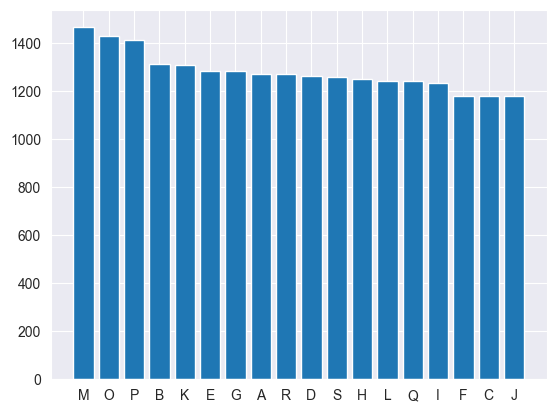

In [6]:
plt.bar(phone_acc_df['ACTIVITY'].value_counts().index, phone_acc_df['ACTIVITY'].value_counts().values);

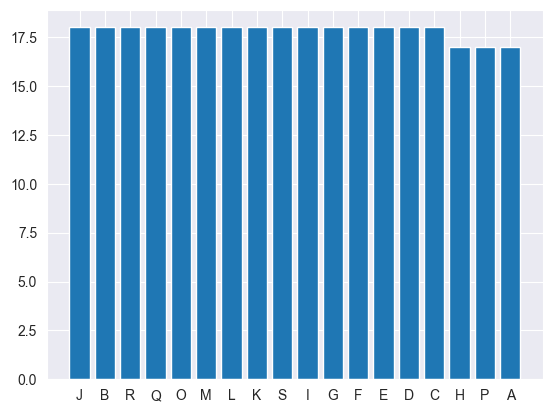

In [92]:
plt.bar(phone_acc_df.loc[1600, 'ACTIVITY'].value_counts().index, phone_acc_df.loc[1600, 'ACTIVITY'].value_counts().values);


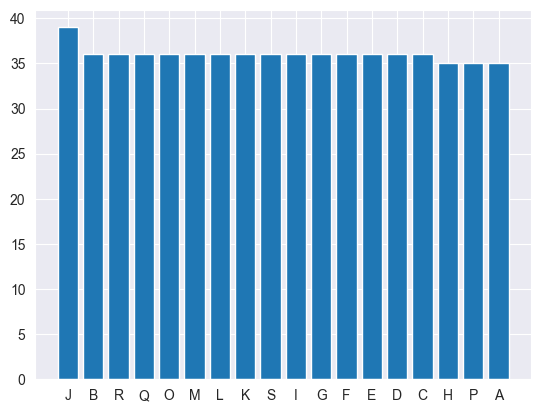

In [93]:
plt.bar(phone_acc_df.loc[1600, 'ACTIVITY'].value_counts().index, phone_acc_df.loc[1600, 'ACTIVITY'].value_counts().values + watch_acc_df.loc[1600, 'ACTIVITY'].value_counts().values);


Each activity was performed for 3 minutes, so that each subject contributed 54 minutes of data?

In [149]:
total_min = phone_acc_df.groupby(by=phone_acc_df.index)['ACTIVITY'].count() * 10 / 60
total_min

class
1600     53.500000
1601     67.833333
1602     70.666667
1603     68.166667
1604     53.500000
1605     67.666667
1606     53.500000
1607     63.833333
1608     80.333333
1609     51.000000
1610    471.333333
1618     50.500000
1619     67.833333
1620     92.500000
1621     68.000000
1622     53.500000
1623     75.833333
1624     53.500000
1625     95.666667
1626     62.500000
1627    129.166667
1628     90.166667
1629     58.000000
1630     53.500000
1631     53.500000
1632     53.500000
1633     71.500000
1634     53.500000
1635    107.333333
1636     53.500000
1637     54.000000
1638     54.000000
1639     54.000000
1640     54.000000
1641    133.833333
1642    119.000000
1643    126.500000
1644    133.833333
1645    133.833333
1646    133.833333
1647     68.166667
1648    133.833333
1649     68.166667
1650    133.833333
Name: ACTIVITY, dtype: float64

In [150]:
total_min.min()

50.5

/var/folders/j8/n524q16s54l6y_vxh70gb9lr0000gs/T/ipykernel_27449/2506902906.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(total_min);


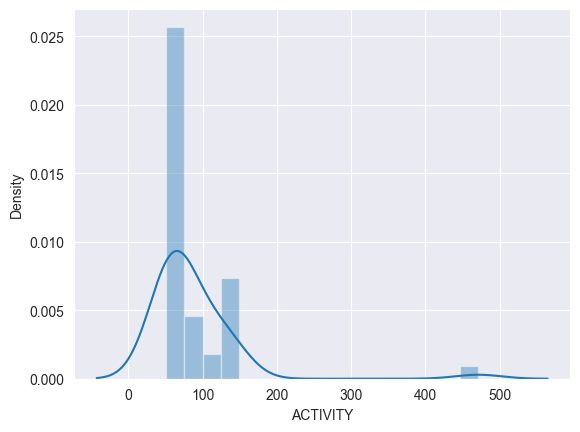

In [151]:
sns.distplot(total_min);

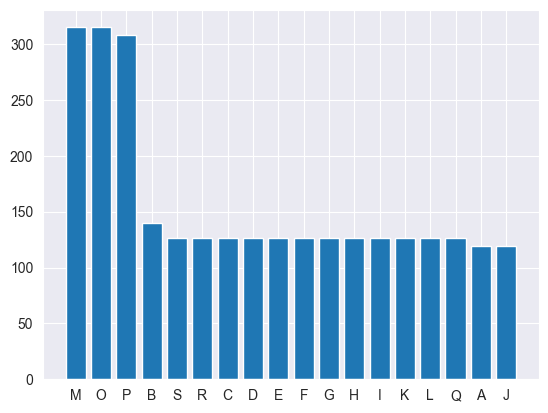

In [152]:
plt.bar(phone_acc_df.loc[phone_acc_df.index[10], 'ACTIVITY'].value_counts().index, phone_acc_df.loc[phone_acc_df.index[10], 'ACTIVITY'].value_counts().values);

### Time series

In [153]:
min_ind = total_min.index[total_min.argmin()]

In [154]:
max_ind = total_min.index[total_min.argmax()]

<Axes: >

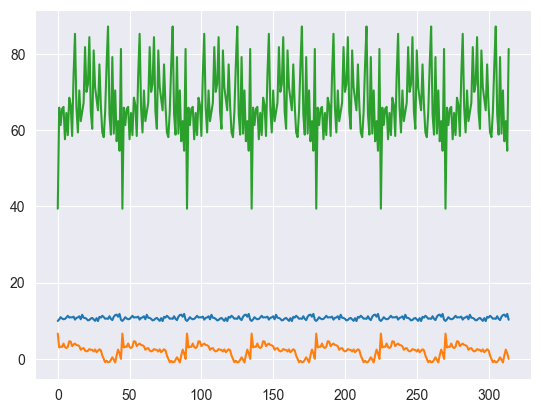

In [156]:
idx = phone_acc_df.loc[max_ind, 'ACTIVITY'] == 'M'
(phone_acc_df.loc[max_ind][idx]).reset_index()['RESULTANT'].plot()
(phone_acc_df.loc[max_ind][idx]).reset_index()['XAVG'].plot()
(phone_acc_df.loc[max_ind][idx]).reset_index()['XPEAK'].plot()

<Axes: >

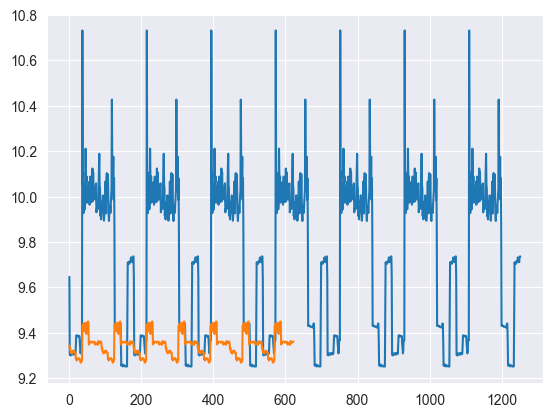

In [157]:
idx = phone_acc_df.loc[max_ind, 'ACTIVITY'].isin({activity_codes.inverse[desc] for desc in activity_groups['hand']})
idx_eat = phone_acc_df.loc[max_ind, 'ACTIVITY'].isin({activity_codes.inverse[desc] for desc in activity_groups['hand-eating']}) 
# idx_eat.mean()

(phone_acc_df.loc[max_ind][idx]).reset_index()['RESULTANT'].plot()
(phone_acc_df.loc[max_ind][idx_eat]).reset_index()['RESULTANT'].plot()
# (phone_acc_df.loc[max_ind][idx]).reset_index()['XAVG'].plot()
# (phone_acc_df.loc[max_ind][idx]).reset_index()['XPEAK'].plot()

<Axes: >

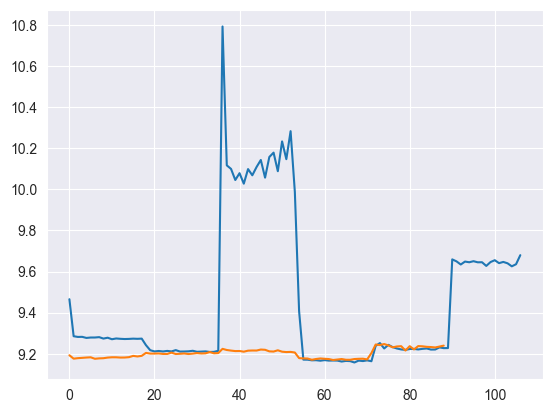

In [158]:
idx = phone_acc_df.loc[min_ind, 'ACTIVITY'].isin({activity_codes.inverse[desc] for desc in activity_groups['hand']})
idx_eat = phone_acc_df.loc[min_ind, 'ACTIVITY'].isin({activity_codes.inverse[desc] for desc in activity_groups['hand-eating']}) 
# idx_eat.mean()

(phone_acc_df.loc[min_ind][idx]).reset_index()['RESULTANT'].plot()
(phone_acc_df.loc[min_ind][idx_eat]).reset_index()['RESULTANT'].plot()
# (phone_acc_df.loc[max_ind][idx]).reset_index()['XAVG'].plot()
# (phone_acc_df.loc[max_ind][idx]).reset_index()['XPEAK'].plot()

<Axes: >

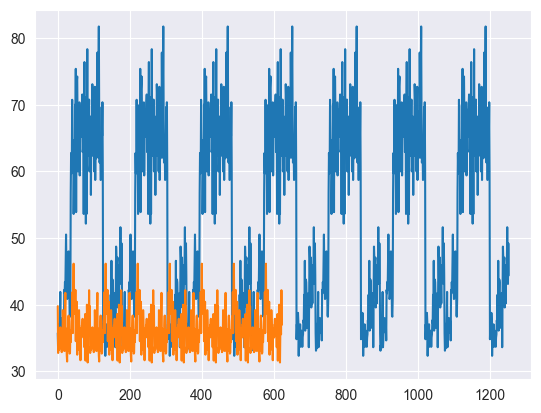

In [161]:
idx = phone_acc_df.loc[max_ind, 'ACTIVITY'].isin({activity_codes.inverse[desc] for desc in activity_groups['hand']})
idx_eat = phone_acc_df.loc[max_ind, 'ACTIVITY'].isin({activity_codes.inverse[desc] for desc in activity_groups['hand-eating']}) 
# idx_eat.mean()

(phone_acc_df.loc[max_ind][idx]).reset_index()['ZPEAK'].plot()
(phone_acc_df.loc[max_ind][idx_eat]).reset_index()['ZPEAK'].plot()
# (phone_acc_df.loc[max_ind][idx]).reset_index()['XAVG'].plot()
# (phone_acc_df.loc[max_ind][idx]).reset_index()['XPEAK'].plot()

<Axes: >

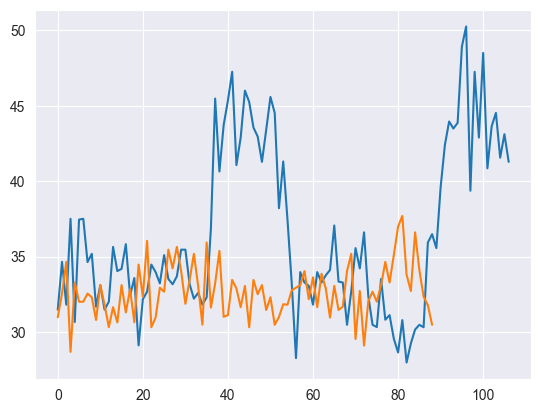

In [162]:
idx = phone_acc_df.loc[min_ind, 'ACTIVITY'].isin({activity_codes.inverse[desc] for desc in activity_groups['hand']})
idx_eat = phone_acc_df.loc[min_ind, 'ACTIVITY'].isin({activity_codes.inverse[desc] for desc in activity_groups['hand-eating']}) 
# idx_eat.mean()

(phone_acc_df.loc[min_ind][idx]).reset_index()['ZPEAK'].plot()
(phone_acc_df.loc[min_ind][idx_eat]).reset_index()['ZPEAK'].plot()
# (phone_acc_df.loc[max_ind][idx]).reset_index()['XAVG'].plot()a
# (phone_acc_df.loc[max_ind][idx]).reset_index()['XPEAK'].plot()